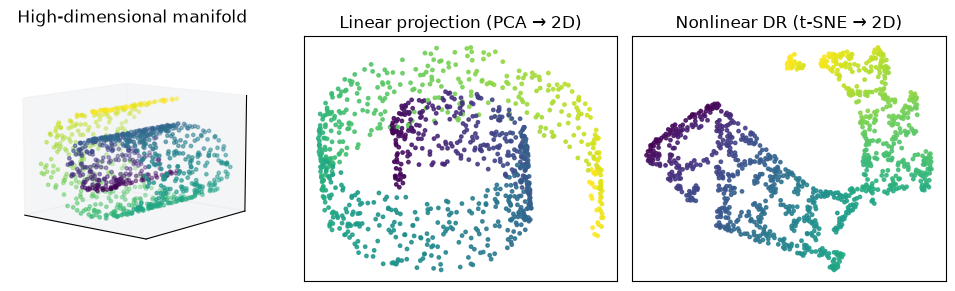

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Generate a colourful Swiss roll
X, t = make_swiss_roll(n_samples=1000, noise=0.05, random_state=3151)

# Linear 2D projection via PCA
pca = PCA(n_components=2, random_state=3151)
X_pca = pca.fit_transform(X)

# Nonlinear 2D embedding via t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="random",
    random_state=3151,
)
X_tsne = tsne.fit_transform(X)

# Build the figure
fig = plt.figure(figsize=(10, 3))
fig.patch.set_facecolor("white")

cmap = "viridis"
point_size = 6
alpha = 0.85

# 1. High-dimensional manifold (Swiss roll in 3D)
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.scatter(
    X[:, 0],
    X[:, 1],
    X[:, 2],
    c=t,
    cmap=cmap,
    s=point_size,
    alpha=alpha,
)
ax1.set_title("High-dimensional manifold", pad=10)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_zticks([])
ax1.view_init(elev=10, azim=130)

# 2. Linear projection (PCA → 2D)
ax2 = fig.add_subplot(1, 3, 2)
ax2.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=t,
    cmap=cmap,
    s=point_size,
    alpha=alpha,
)
ax2.set_title("Linear projection (PCA → 2D)")
ax2.set_xticks([])
ax2.set_yticks([])

# 3. Nonlinear DR (t-SNE → 2D)
ax3 = fig.add_subplot(1, 3, 3)
ax3.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=t,
    cmap=cmap,
    s=point_size,
    alpha=alpha,
)
ax3.set_title("Nonlinear DR (t-SNE → 2D)")
ax3.set_xticks([])
ax3.set_yticks([])

plt.tight_layout()

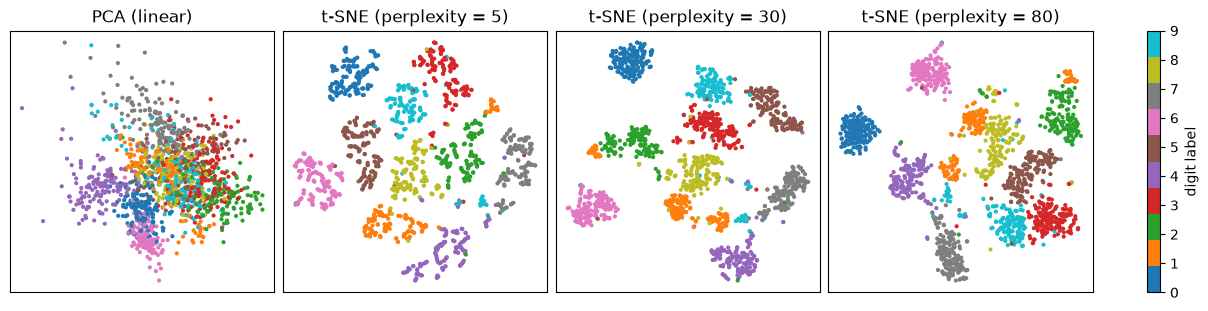

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Load and subsample digits for speed
rng = np.random.default_rng(3151)
digits = load_digits()
X_full, y_full = digits.data, digits.target

idx = rng.choice(len(X_full), size=1500, replace=False)
X = X_full[idx]
y = y_full[idx]

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# Linear baseline: PCA → 2D
pca2 = PCA(n_components=2, random_state=3151)
X_pca = pca2.fit_transform(X_scaled)

# Nonlinear: t-SNE with different perplexities
perplexities = [5, 30, 80]
embeddings = []

for p in perplexities:
    tsne = TSNE(
        n_components=2,
        perplexity=p,
        learning_rate="auto",
        init="random",
        random_state=3151,
    )
    Z = tsne.fit_transform(X_scaled)
    embeddings.append(Z)

# Pretty 4-panel figure
fig, axes = plt.subplots(1, 4, figsize=(12, 3),constrained_layout=True )
titles = [
    "PCA (linear)",
    "t-SNE (perplexity = 5)",
    "t-SNE (perplexity = 30)",
    "t-SNE (perplexity = 80)",
]

scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=4, cmap="tab10")
axes[0].set_title(titles[0])
axes[0].set_xticks([])
axes[0].set_yticks([])

for ax, Z, title in zip(axes[1:], embeddings, titles[1:]):
    ax.scatter(Z[:, 0], Z[:, 1], c=y, s=4, cmap="tab10")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(scatter, ax=axes, label="digit label", fraction=0.046)
#plt.tight_layout()

In [33]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

rng = np.random.default_rng(3151)

digits = load_digits()
X_full, y_full = digits.data, digits.target

# Subsample for speed
idx = rng.choice(len(X_full), size=1000, replace=False)
X = X_full[idx]
y = y_full[idx]

X_scaled = StandardScaler().fit_transform(X)

pca2 = PCA(n_components=2, random_state=3151)
X_pca = pca2.fit_transform(X_scaled)

var_table = pd.DataFrame(
    {
        "component": [1, 2],
        "explained_variance_ratio": pca2.explained_variance_ratio_,
    }
)
var_table

,component,explained_variance_ratio
0,1,0.122386
1,2,0.096081


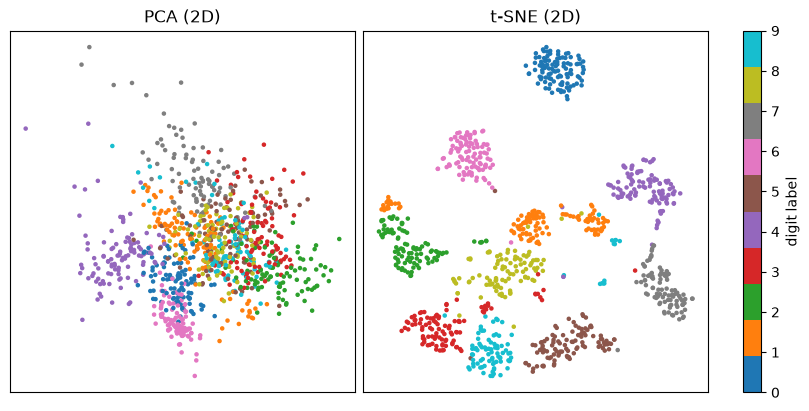

In [34]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="random",
    random_state=3151,
)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(8, 4),constrained_layout=True)

scatter0 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=5, cmap="tab10")
axes[0].set_title("PCA (2D)")
axes[0].set_xticks([])
axes[0].set_yticks([])

axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, s=5, cmap="tab10")
axes[1].set_title("t-SNE (2D)")
axes[1].set_xticks([])
axes[1].set_yticks([])

fig.colorbar(scatter0, ax=axes, label="digit label", fraction=0.046)
#plt.tight_layout()

In [35]:
import pandas as pd

dr_summary = pd.DataFrame(
    [
        ("PCA", "linear", None, None),
        ("t-SNE", "nonlinear", "perplexity=30", None),
        ("UMAP", "nonlinear", "n_neighbors=15", "min_dist=0.1"),
    ],
    columns=["method", "type", "locality_hyperparam", "density_hyperparam"],
)
dr_summary

,method,type,locality_hyperparam,density_hyperparam
0,PCA,linear,NaN,NaN
1,t-SNE,nonlinear,perplexity=30,NaN
2,UMAP,nonlinear,n_neighbors=15,min_dist=0.1
